# Tangram tutorial

The `mode="cells"` part of [Tangram's tutorial](https://github.com/broadinstitute/Tangram/blob/4c68995a418f41dc8caef567598c4d9b47781a13/tutorial_tangram_with_squidpy.ipynb), which maps the
`sc_mouse_cortex` scRNA-seq reference onto the cortex of the `visium_fluo` Visium section, written against
[`squidpy.experimental.tl.impute_tangram`](https://github.com/scverse/squidpy/blob/main/src/squidpy/experimental/tl/_impute_tangram.py).

The port maps cells, keeps the mapping and projects genes, so the tutorial's cell-type maps, gene plots and score
of every gene are reproduced here. Its `mode="constrained"`, segmentation and deconvolution are not part of the
port.
The last section runs upstream Tangram from this repository's pinned copy on the same inputs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

import squidpy as sq

sc.settings.set_figure_params(dpi=50)  # the panels sit on the section's high-resolution image

In [2]:
adata_st = sq.datasets.visium_fluo_adata_crop()
adata_st = adata_st[adata_st.obs.cluster.isin([f"Cortex_{i}" for i in np.arange(1, 5)])].copy()
adata_sc = sq.datasets.sc_mouse_cortex()

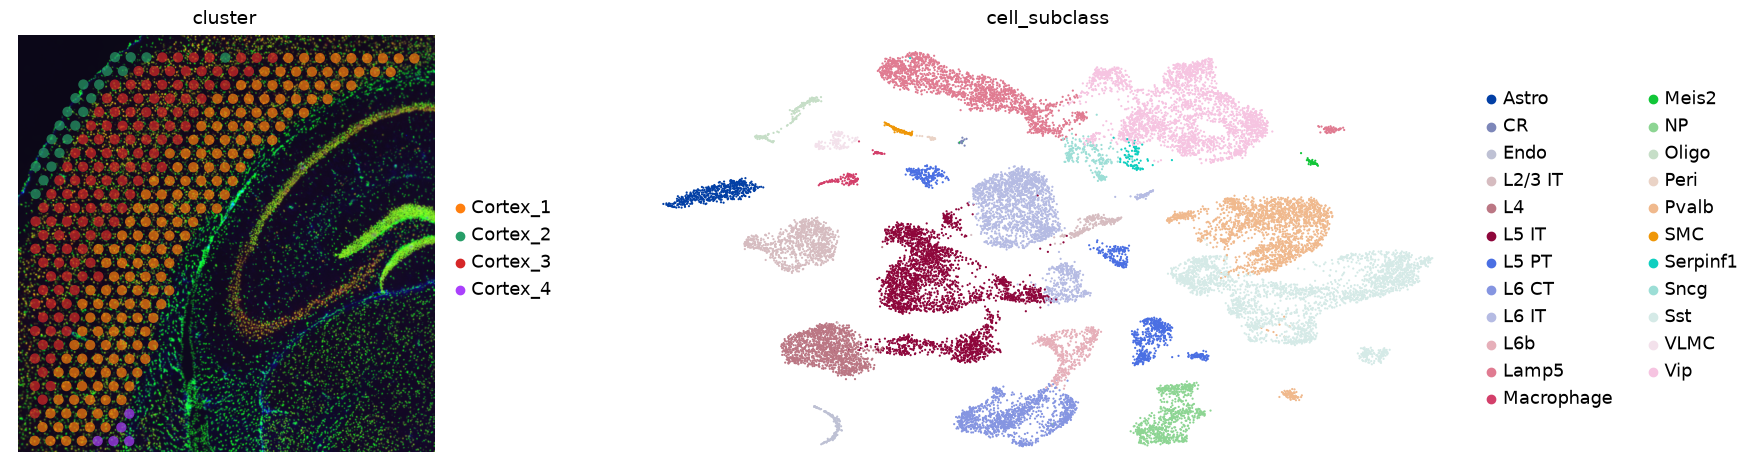

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(20, 5))
sc.pl.spatial(adata_st, color="cluster", alpha=0.7, frameon=False, show=False, ax=axs[0])
sc.pl.umap(adata_sc, color="cell_subclass", size=10, frameon=False, show=False, ax=axs[1])
plt.tight_layout()

The tutorial trains on the top 100 marker genes of each cell subclass.

In [4]:
sc.tl.rank_genes_groups(adata_sc, groupby="cell_subclass", use_raw=False)
markers_df = pd.DataFrame(adata_sc.uns["rank_genes_groups"]["names"]).iloc[0:100, :]
markers = list(np.unique(markers_df.melt().value.values))
len(markers)

1401

`tg.pp_adatas` lowercases every gene name, so that names match across species capitalizations; `impute_tangram`
compares names as given, so they are lowercased here instead.

`impute_tangram` trains on every gene the two datasets share, so the query passed to it is the section restricted
to the marker genes. One consequence: its `"rna_count_based"` prior counts those genes only, where `tg.pp_adatas`
counts every gene of the section.

In [5]:
for adata in (adata_sc, adata_st):
    adata.var_names = adata.var_names.str.lower()
    adata.var_names_make_unique()

training = sorted(set(map(str.lower, markers)) & set(adata_st.var_names))
shared = sorted(set(adata_sc.var_names) & set(adata_st.var_names))
f"{len(training)} training genes, {len(shared) - len(training)} test genes"

'1281 training genes, 13822 test genes'

In [6]:
query = adata_st[:, training].copy()
sq.experimental.tl.impute_tangram(adata_sc, query, genes=shared, density_prior="rna_count_based", n_epochs=500, rng=0)
adata_st.obsm["tangram"] = query.obsm["tangram"]
mapping = query.obsm["tangram_mapping"]  # query spots x reference cells
mapping.shape

(324, 21697)

## Cell types

`tg.project_cell_annotations` sums the mapping over the cells of each subclass, and `tg.plot_cell_annotation_sc`
shows each subclass's share of every spot, clipped at the 2nd and 98th percentile (`perc=0.02`) and scaled to
[0, 1].

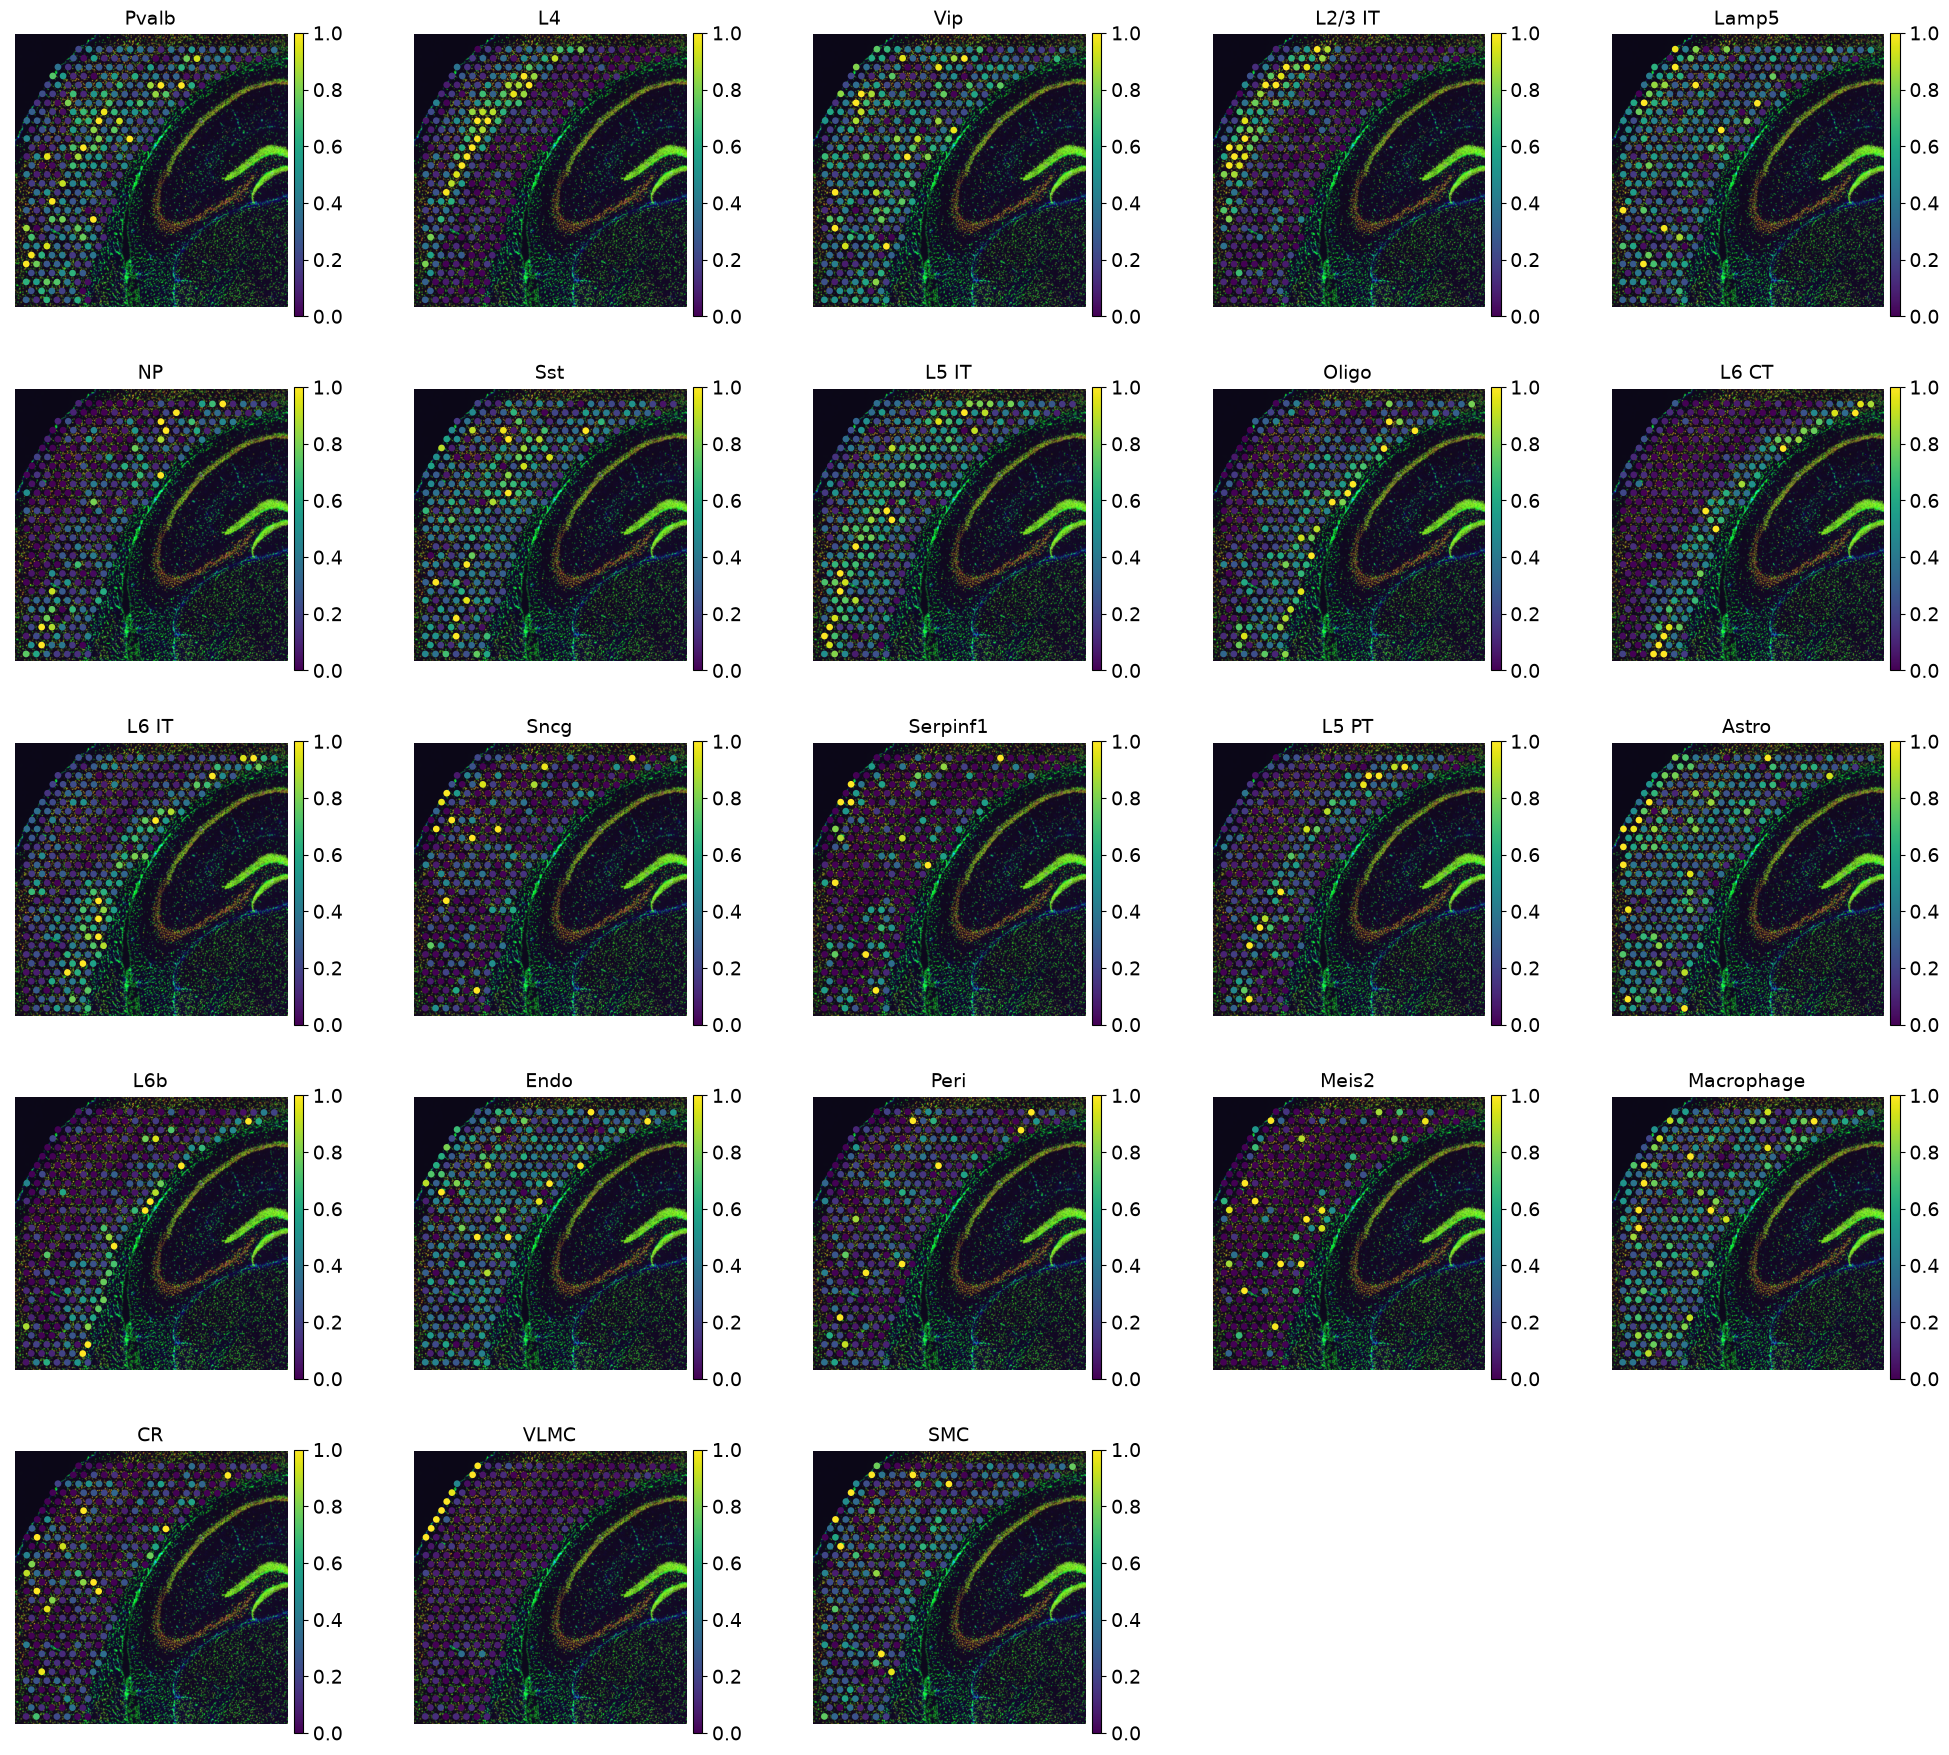

In [7]:
def scaled(df, perc=0.02):
    # each column clipped at its `perc` and `1 - perc` quantiles and scaled to [0, 1], as Tangram's plots do
    lo, hi = df.quantile(perc), df.quantile(1 - perc)
    return ((df.clip(lo, hi, axis=1) - lo) / (hi - lo)).fillna(0)


annotation = pd.get_dummies(adata_sc.obs["cell_subclass"]).astype(float)
cell_types = pd.DataFrame(mapping @ annotation.to_numpy(), index=adata_st.obs_names, columns=annotation.columns)
annotation_list = list(pd.unique(adata_sc.obs["cell_subclass"]))
adata_st.obs[annotation_list] = scaled(cell_types[annotation_list])
sc.pl.spatial(adata_st, color=annotation_list, ncols=5, frameon=False, vmin=0, vmax=1, cmap="viridis")
adata_st.obs.drop(columns=annotation_list, inplace=True)

## Measured and predicted genes

`tg.plot_genes_sc` shows each gene measured and predicted on the tissue, each scaled to its own range. First three
training genes, then the test genes the tutorial picks; a gene the current release of the datasets no longer has
in both is skipped, with a note.

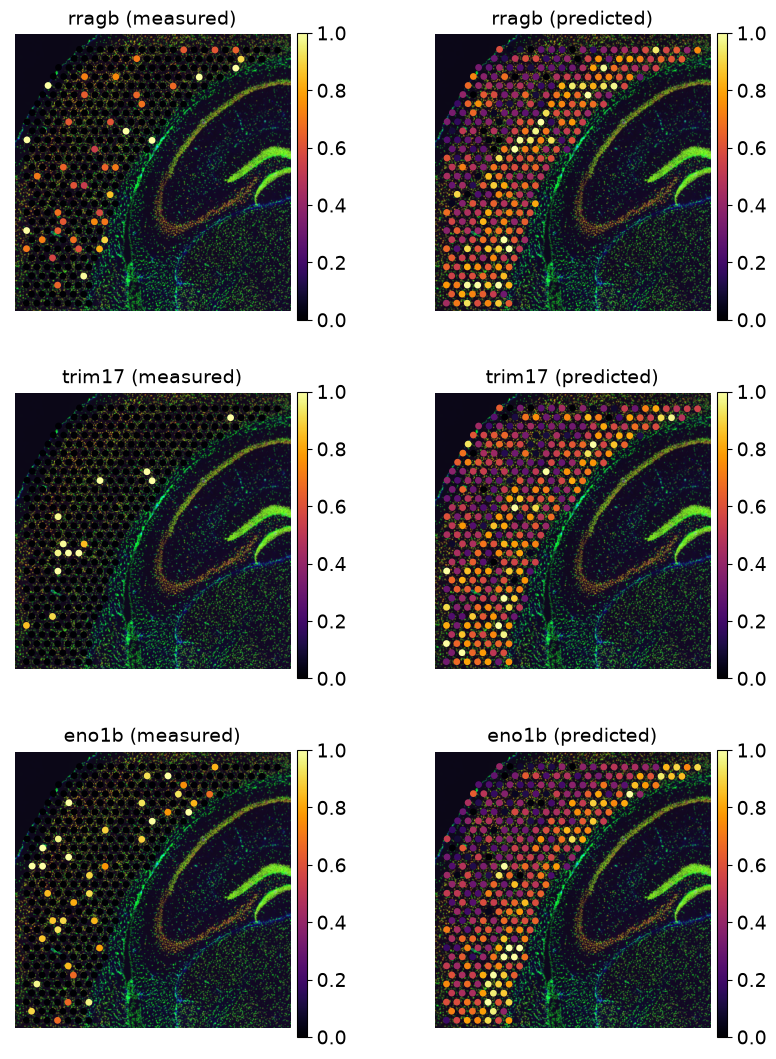

In [8]:
def plot_genes(genes):
    if missing := [g for g in genes if g not in shared]:
        print(f"not measured in this version of the datasets, skipped: {missing}")
    if not (genes := [g for g in genes if g in shared]):
        return
    measured = scaled(adata_st[:, genes].to_df()).add_suffix(" (measured)")
    predicted = scaled(adata_st.obsm["tangram"][genes]).add_suffix(" (predicted)")
    adata_st.obs[measured.columns] = measured
    adata_st.obs[predicted.columns] = predicted
    columns = [c for pair in zip(measured.columns, predicted.columns, strict=True) for c in pair]
    sc.pl.spatial(adata_st, color=columns, ncols=2, frameon=False, vmin=0, vmax=1, cmap="inferno")
    adata_st.obs.drop(columns=columns, inplace=True)


plot_genes(["rragb", "trim17", "eno1b"])

In [9]:
plot_genes(['loc102633833', 'gm5700', 'gm8292'])

not measured in this version of the datasets, skipped: ['loc102633833', 'gm5700', 'gm8292']


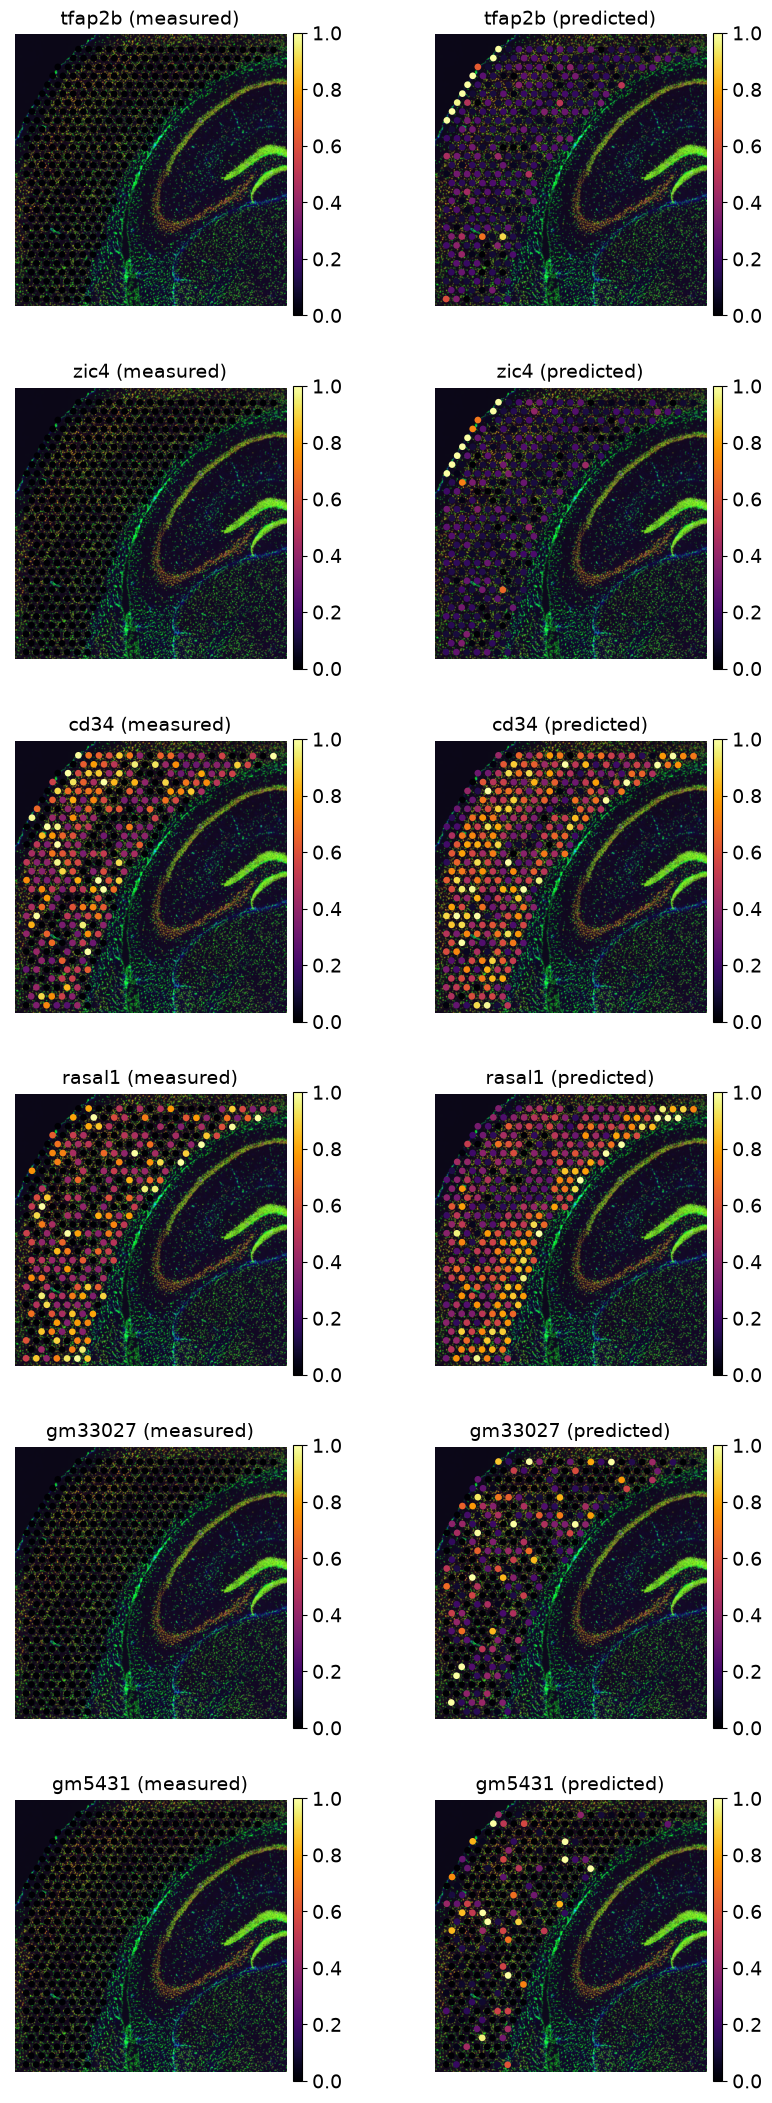

In [10]:
plot_genes(['tfap2b', 'zic4', 'cd34', 'rasal1', 'gm33027', 'gm5431'])

## Scores of all genes

`tg.compare_spatial_geneexp` scores each gene by the cosine similarity of its measured and predicted expression
across spots, and plots it against how sparse the gene is in the section.

,count,mean,std,min,25%,50%,75%,max
is_training,,,,,,,,
False,13505.0,0.458061,0.268343,0.000006,0.220106,0.455199,0.671241,0.998319
True,1280.0,0.737392,0.173196,0.134819,0.627000,0.756878,0.871339,0.997880


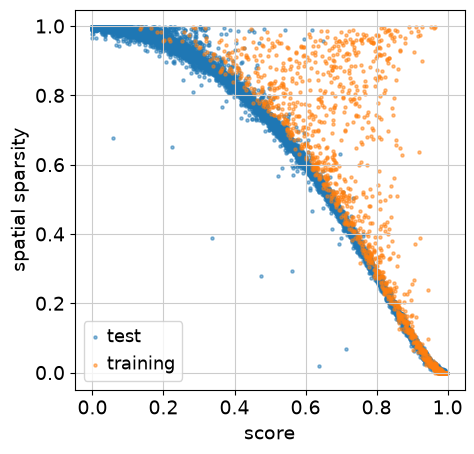

In [11]:
def scores(predicted):
    measured = adata_st[:, predicted.columns].to_df()
    norms = np.linalg.norm(measured, axis=0) * np.linalg.norm(predicted, axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        return pd.Series((measured.to_numpy() * predicted.to_numpy()).sum(0) / norms, index=predicted.columns)


df_all_genes = pd.DataFrame(
    {
        "score": scores(adata_st.obsm["tangram"]),
        "sparsity_sp": 1 - np.asarray((adata_st[:, shared].X > 0).mean(0)).ravel(),
        "is_training": [g in training for g in shared],
    }
)
fig, ax = plt.subplots(figsize=(5, 5))
for is_training, group in df_all_genes.groupby("is_training"):
    ax.scatter(group.score, group.sparsity_sp, s=5, alpha=0.5, label="training" if is_training else "test")
ax.set(xlabel="score", ylabel="spatial sparsity")
ax.legend()
df_all_genes.groupby("is_training").score.describe()

## Against upstream

Upstream Tangram from this repository's pinned copy (`vendor/Tangram`), on the same reference, the same
marker-restricted section and the same settings, through `squidpy_ports.tangram.upstream.run`: the tutorial's
`pp_adatas` → `map_cells_to_space` → `project_genes`. Each implementation draws its own random start, so the two
mappings differ in their details; the gene scores they reach are what should agree.

In [12]:
from squidpy_ports._common import Imputation
from squidpy_ports.tangram import upstream

test = [g for g in shared if g not in set(training)]
data = Imputation(
    ref=adata_sc[:, training + test].X.toarray(),
    query=adata_st[:, training].X.toarray(),
    truth=adata_st[:, test].X.toarray(),
    genes=training + test,
)
upstream_res = upstream.run(upstream.load(), data, num_epochs=500, density_prior="rna_count_based", random_state=0)
upstream_scores = scores(pd.DataFrame(upstream_res["imputed"], index=adata_st.obs_names, columns=test))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(upstream_scores, df_all_genes.score[test], s=5, alpha=0.5)
ax.axline((0, 0), slope=1, color="grey", lw=1)
ax.set(xlabel="upstream score", ylabel="squidpy score", title="test genes")
print(f"median test score: squidpy {df_all_genes.score[test].median():.3f}, upstream {upstream_scores.median():.3f}")
print(f"correlation of the per-gene scores: {np.corrcoef(upstream_scores.fillna(0), df_all_genes.score[test].fillna(0))[0, 1]:.3f}")

median test score: squidpy 0.455, upstream 0.455
correlation of the per-gene scores: 0.999
